# NIVELL 1: ANÀLISI DE DADES

Grup *Xurrasco 26/9*

---

**Configuració prèvia**

Imports necessaris per a l'execució del Notebook

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import datetime
import os
import json

# Creació de la carpeta per als gràfics si no existeix
directori_grafics = 'grafics_analisi'
if not os.path.exists(directori_grafics):
    os.makedirs(directori_grafics)
    print(f"S'ha creat el directori: {directori_grafics}")
else:
    print(f"El directori '{directori_grafics}' ja existeix.")

df_sessions = pd.read_csv('paquet/sessions.csv')
df_aules = pd.read_csv('paquet/aules.csv')
df_proposta = pd.read_csv("paquet/proposta_partida.csv")

El directori 'grafics_analisi' ja existeix.


---

### Quina és la ocupació actual de les aules?

Per respondre a aquesta pregunta, hem creat un mapa de calor (*heatmap*) per cada semestre i finestra (matí o tarda). D'aquesta forma podem mostrar d'una manera visual quina és la **ocupació actual** d'aules de l'Escola d'Enginyeria.

Generant mapa de calor per: 1r Semestre - Matí (8:30-14:30)...


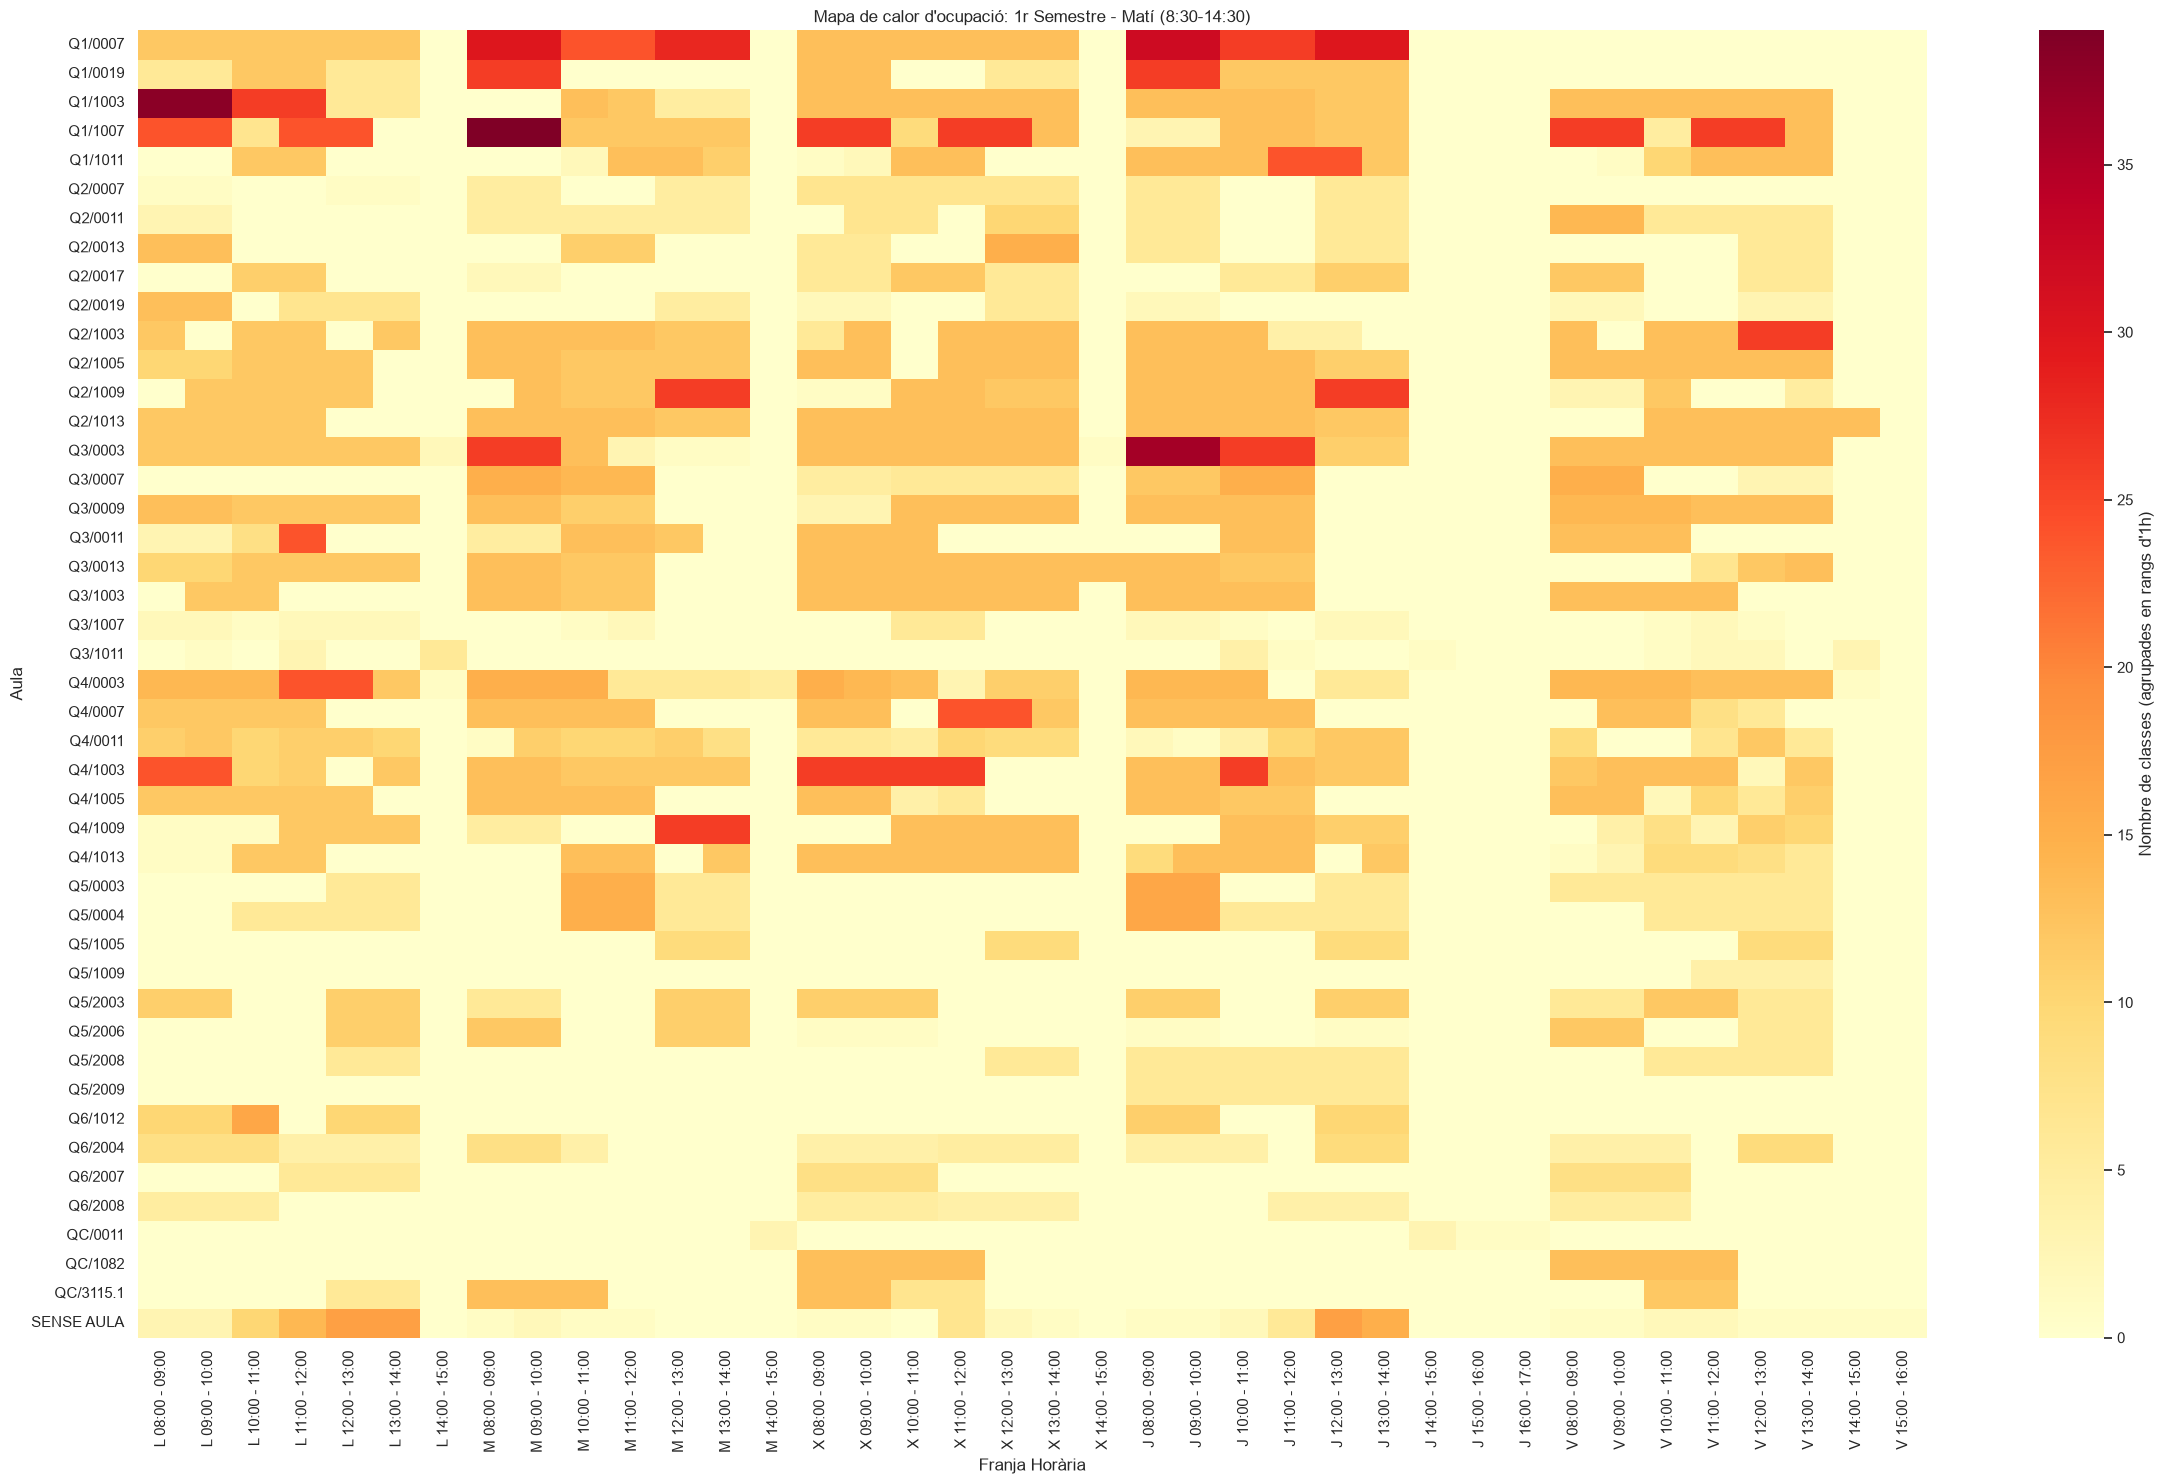

-> Imatge desada com: heatmap_S1_mati.png

Generant mapa de calor per: 1r Semestre - Tarda (14:30-21:00)...


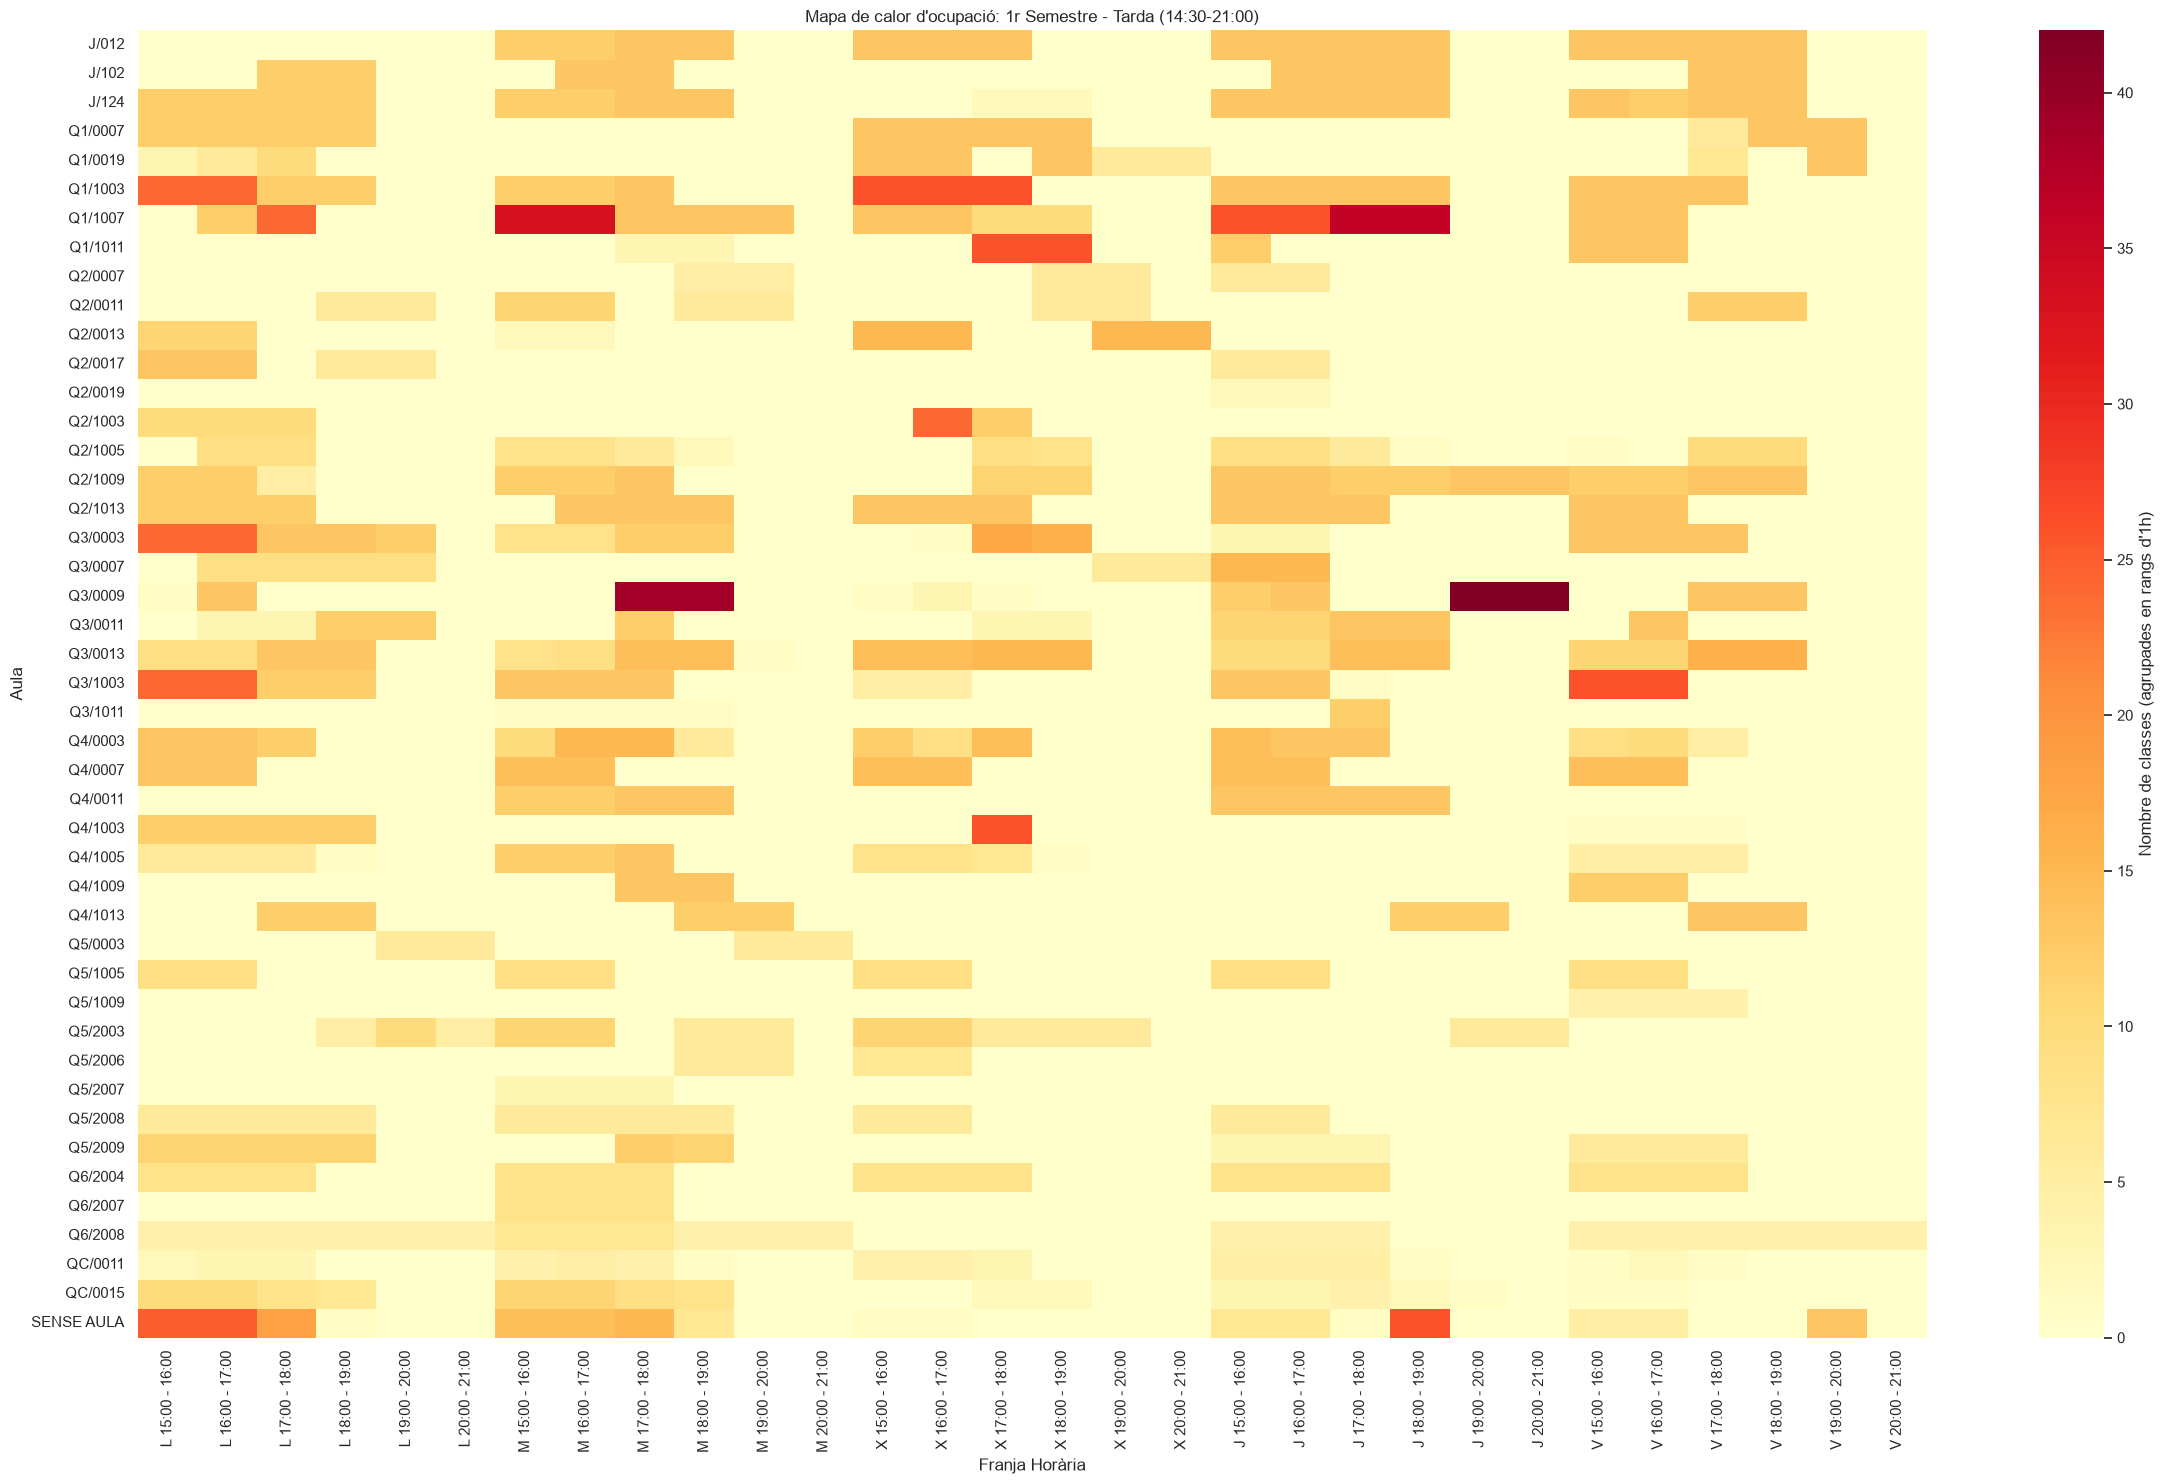

-> Imatge desada com: heatmap_S1_tarda.png

Generant mapa de calor per: 2n Semestre - Matí (8:30-14:30)...


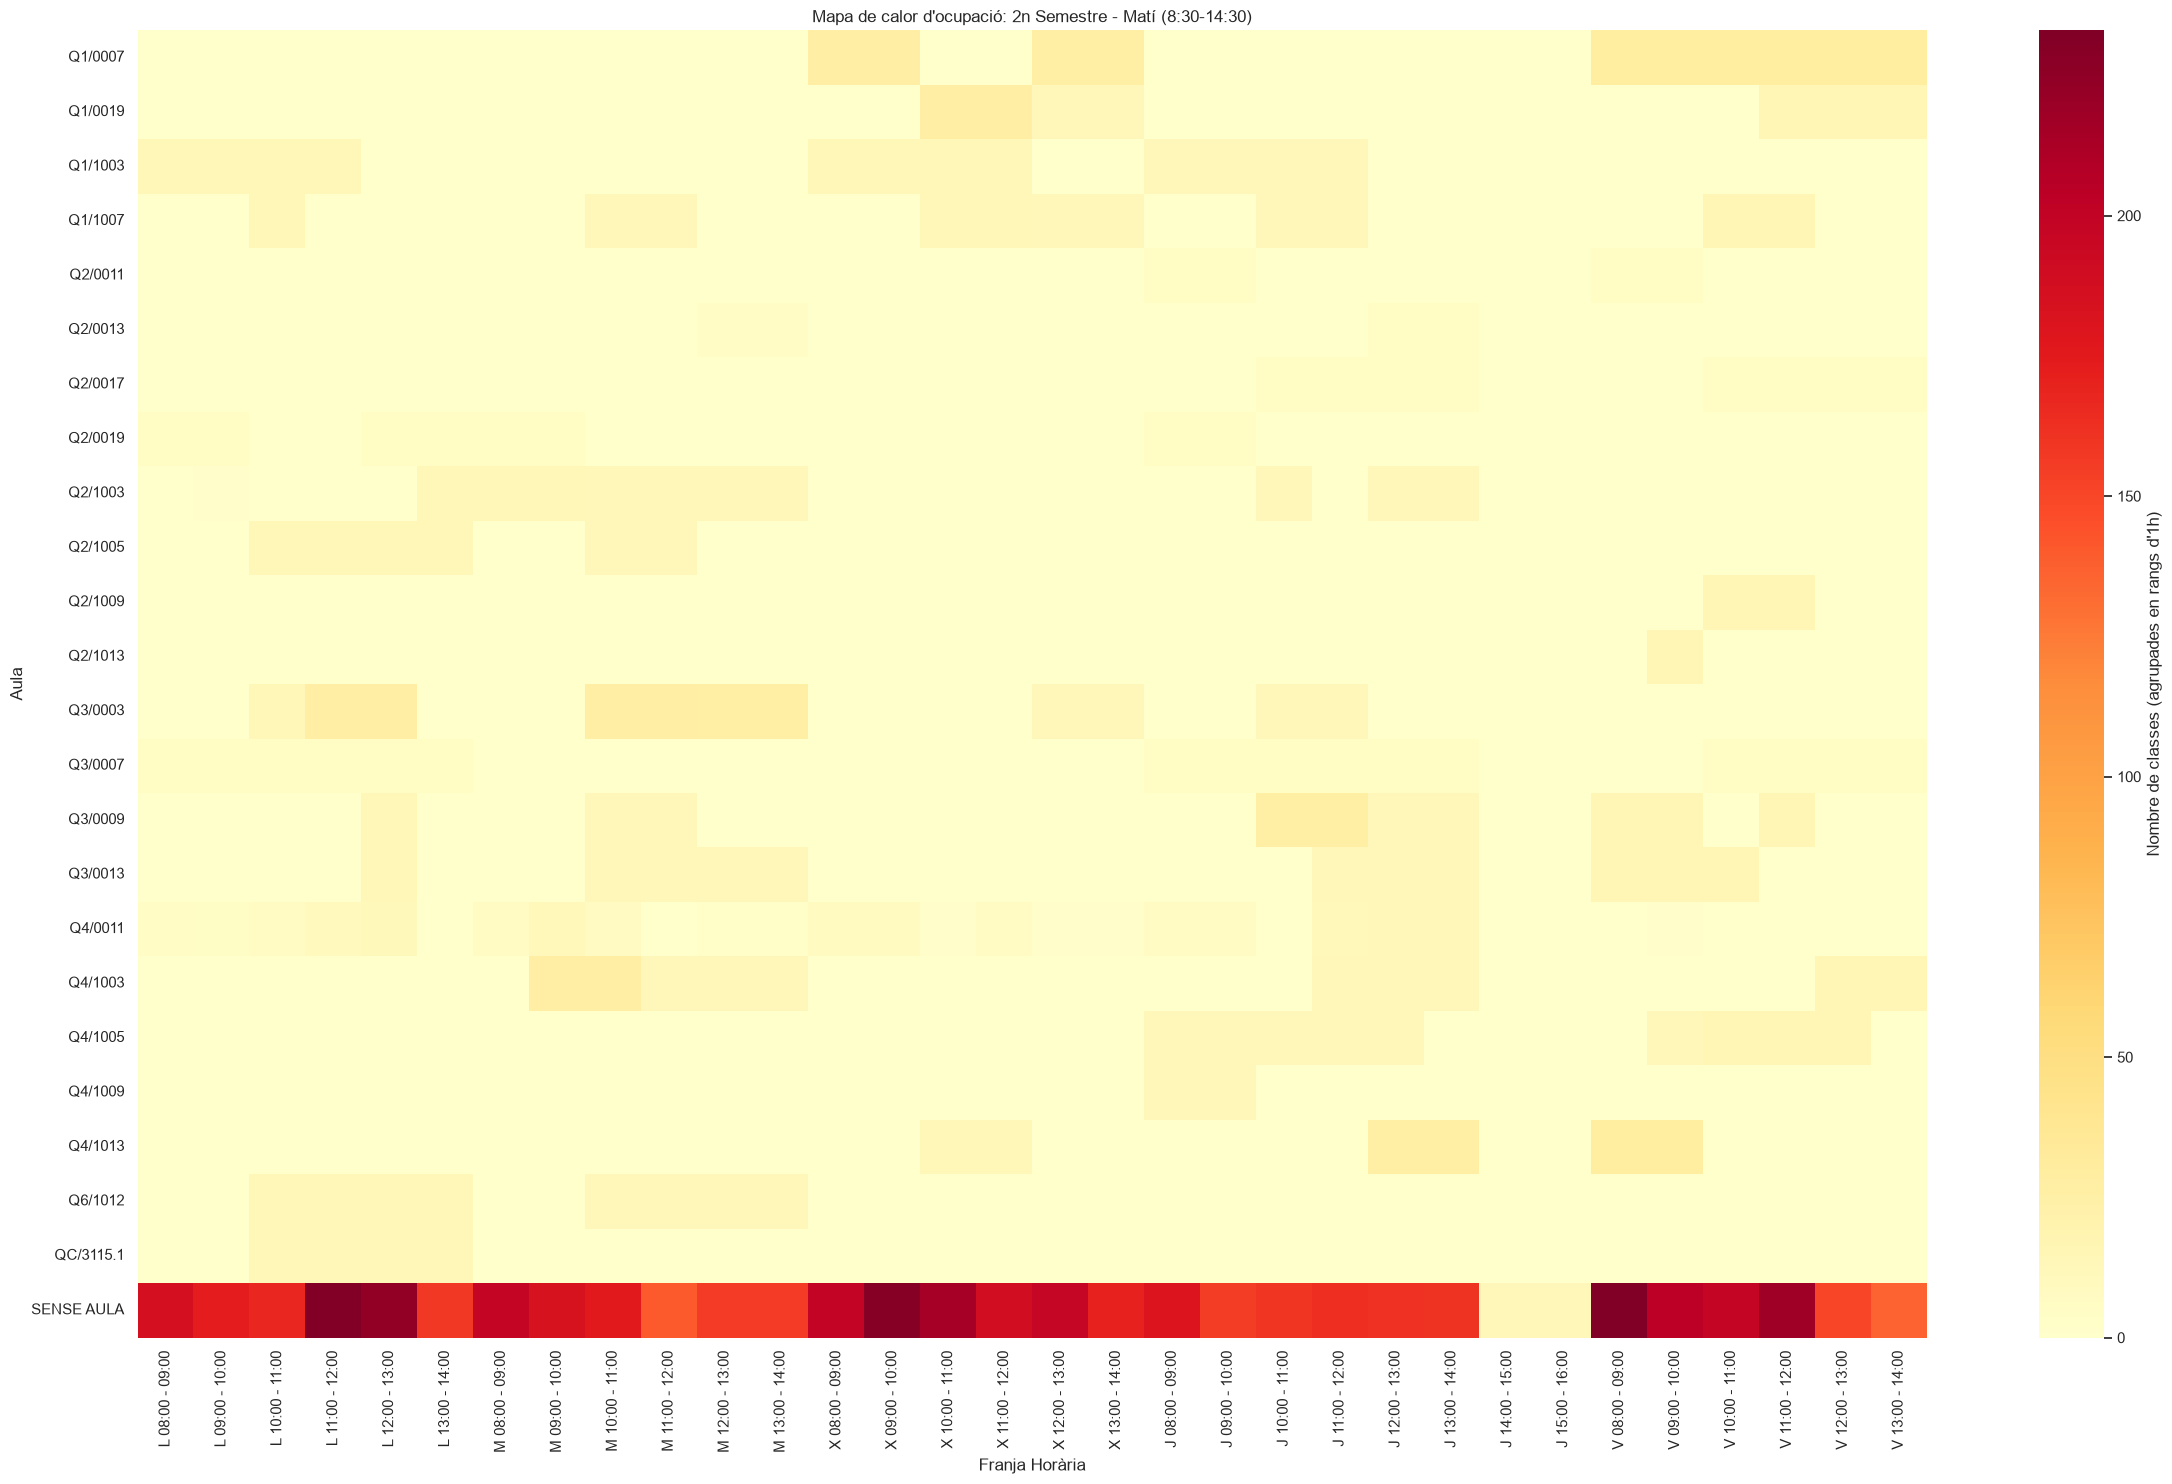

-> Imatge desada com: heatmap_S2_mati.png

Generant mapa de calor per: 2n Semestre - Tarda (14:30-21:00)...


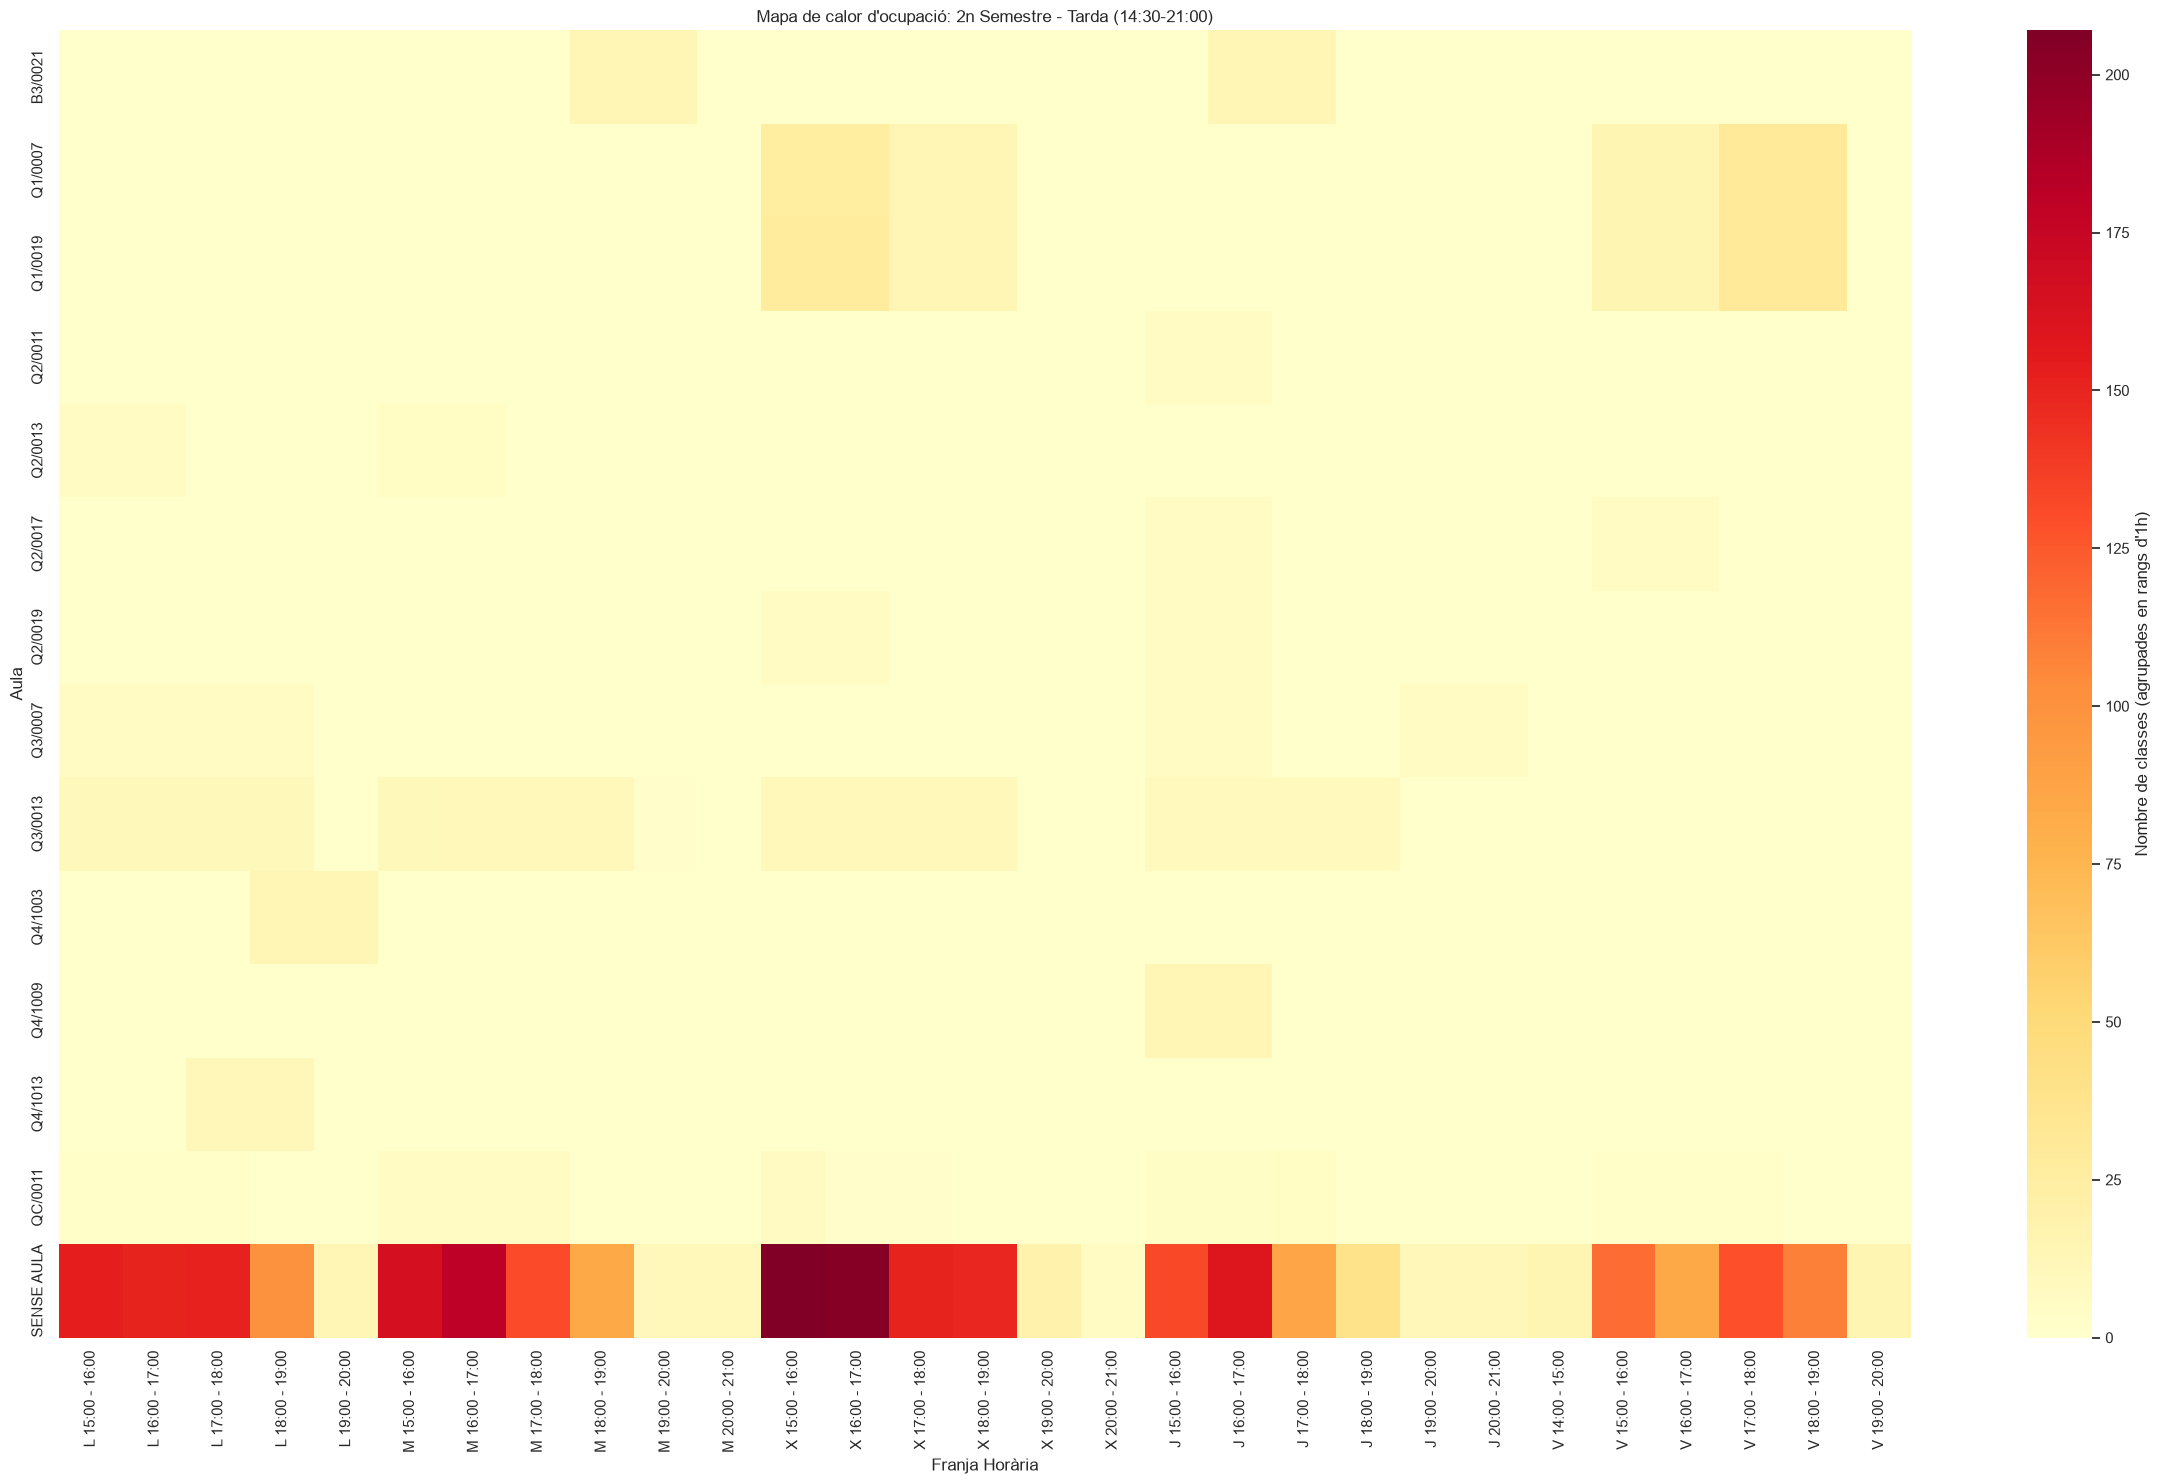

-> Imatge desada com: heatmap_S2_tarda.png



In [10]:
sessions = df_sessions.copy()
sessions['aula_plot'] = sessions['aula_partida'].fillna('SENSE AULA')

# 2. Classificar les sessions en Matí (abans de 14:30) o Tarda (14:30 o després)
sessions['hora_dt'] = pd.to_datetime(sessions['h_ini'].astype(str), format='%H:%M').dt.time
limit_time = datetime.time(14, 30) # 14:30

sessions['torn'] = sessions['hora_dt'].apply(lambda x: 'Matí' if x < limit_time else 'Tarda')

def rangs_hores(row):
    try:
        start = pd.to_datetime(str(row['h_ini']), format='%H:%M').floor('h')
        durada = int(row['durada_min'])
        num_blocs = max(1, round(durada / 60.0))
        slots = pd.date_range(start, periods=num_blocs, freq='1h')
        return [(t.strftime('%H:00') + " - " + (t + pd.Timedelta(hours=1)).strftime('%H:00')) for t in slots]
    except Exception as e:
        return [str(row['h_ini'])]

def plot_heatmap(semestre_codi, torn, titol, nom_arxiu):
    df_filtre = sessions[(sessions['semestre'] == semestre_codi) & (sessions['torn'] == torn)].copy()
    
    if df_filtre.empty:
        print(f"No hi ha dades per mostrar a: {titol}")
        return
    
    df_filtre['rangs_ocupats'] = df_filtre.apply(rangs_hores, axis=1)
    df_expanded = df_filtre.explode('rangs_ocupats')
    
    ocupacio = df_expanded.groupby(['aula_plot', 'dia', 'rangs_ocupats']).size().reset_index(name='sessions')
    
    dies_ordre = ['L', 'M', 'X', 'J', 'V']
    ocupacio['dia'] = pd.Categorical(ocupacio['dia'], categories=dies_ordre, ordered=True)
    
    ocupacio = ocupacio.sort_values(['dia', 'rangs_ocupats'])
    ocupacio['franja_eix'] = ocupacio['dia'].astype(str) + " " + ocupacio['rangs_ocupats']
    
    ordre_franges = ocupacio['franja_eix'].unique()
    
    pivot_df = ocupacio.pivot(index='aula_plot', columns='franja_eix', values='sessions').fillna(0)
    pivot_df = pivot_df.reindex(columns=ordre_franges)
    
    plt.figure(figsize=(24, 15))
    sns.heatmap(pivot_df, cmap='YlOrRd', cbar_kws={'label': 'Nombre de classes (agrupades en rangs d\'1h)'})
    plt.title(f'Mapa de calor d\'ocupació: {titol}')
    plt.xlabel('Franja Horària')
    plt.ylabel('Aula')
    plt.tight_layout()
    
    # Exportar a imatge (png amb alta resolució)
    plt.savefig(f"{directori_grafics}/{nom_arxiu}", dpi=300, bbox_inches='tight')
    plt.show()

# 5. Executar el bucle per generar els 4 heatmaps
configuracions = [
    ('C/1', 'Matí', '1r Semestre - Matí (8:30-14:30)', 'heatmap_S1_mati.png'),
    ('C/1', 'Tarda', '1r Semestre - Tarda (14:30-21:00)', 'heatmap_S1_tarda.png'),
    ('C/2', 'Matí', '2n Semestre - Matí (8:30-14:30)', 'heatmap_S2_mati.png'),
    ('C/2', 'Tarda', '2n Semestre - Tarda (14:30-21:00)', 'heatmap_S2_tarda.png')
]

for semestre, torn, titol, arxiu in configuracions:
    print(f"Generant mapa de calor per: {titol}...")
    plot_heatmap(semestre, torn, titol, arxiu)
    print(f"-> Imatge desada com: {arxiu}\n")

Veiem que certes aules tenen molt més ús que altres. En el cas del 2n semestre, encara falten moltes sessions per assignar, així que no apareixen gaires.

Veient aquesta situació, anem a veure si aquestes aules amb major utilització tenen alguna característica en comú (per exemple, més capacitat)

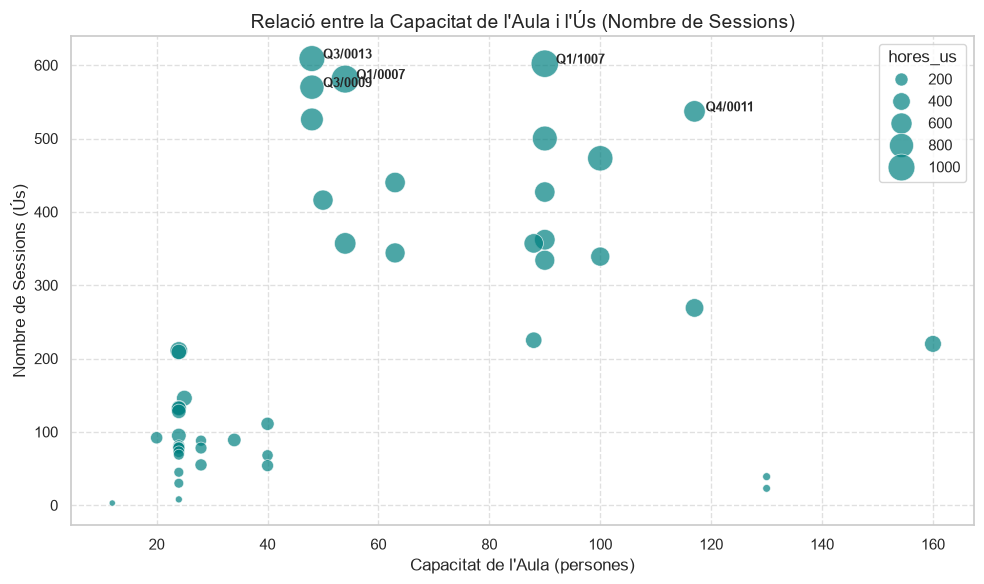

In [11]:
usage_df = df_sessions['aula_partida'].value_counts().reset_index()
usage_df.columns = ['aula', 'num_sessions']

sessions = df_sessions.copy()

sessions['durada_hores'] = sessions['durada_min'] / 60.0
usage_hours_df = sessions.groupby('aula_partida')['durada_hores'].sum().reset_index()
usage_hours_df.columns = ['aula', 'hores_us']

usage_stats = pd.merge(usage_df, usage_hours_df, on='aula')

merged_df = pd.merge(usage_stats, df_aules[['aula', 'capacitat', 'tipus']], on='aula', how='left')

plt.figure(figsize=(10, 6))
sns.scatterplot(data=merged_df, x='capacitat', y='num_sessions', size='hores_us', sizes=(20, 400), alpha=0.7, color='teal')

plt.title('Relació entre la Capacitat de l\'Aula i l\'Ús (Nombre de Sessions)', fontsize=14)
plt.xlabel('Capacitat de l\'Aula (persones)', fontsize=12)
plt.ylabel('Nombre de Sessions (Ús)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

top5 = merged_df.sort_values(by='num_sessions', ascending=False).head(5)
for i in range(top5.shape[0]):
    plt.text(top5['capacitat'].iloc[i] + 2, top5['num_sessions'].iloc[i], 
             top5['aula'].iloc[i], fontsize=9, weight='bold')

plt.tight_layout()
plt.savefig(f'{directori_grafics}/relacio_capacitat_us.png')
plt.show()

---

### Quantes sessions estan al torn 'incorrecte'?

Creem una matriu amb les sessions de matí que estan al matí, les de matí que estan a la tarda, i el mateix per les sessions de tarda.

Matriu de resultats:
Torn Real (torn_actual)      mati  tarda
Torn Teòric (torn_requerit)             
mati                         7131   2223
tarda                        4532   3140


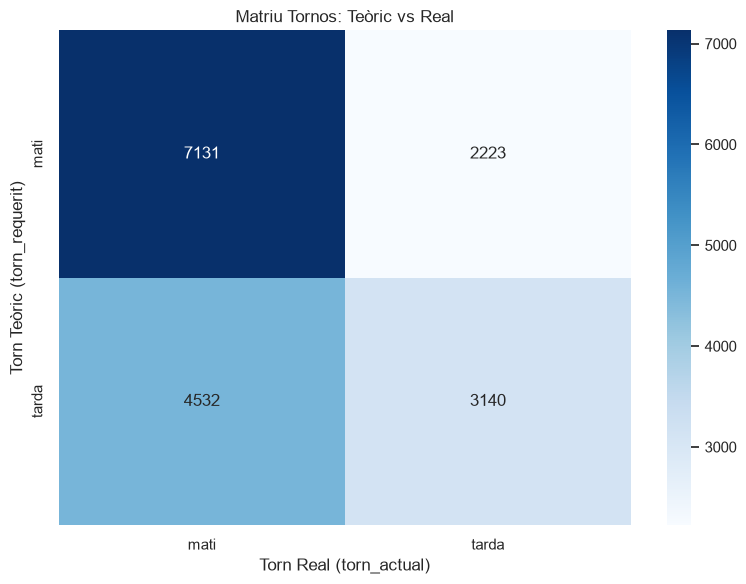

In [12]:
sessions = df_sessions.copy()
sessions = sessions.dropna(subset=['h_ini', 'torn_requerit']).copy()

def calcular_torn(hora_str):
    try:
        hores, minuts = map(int, str(hora_str).split(':'))
        if hores * 60 + minuts < 870:
            return 'mati'
        else:
            return 'tarda'
    except:
        return None

sessions['torn_actual'] = sessions['h_ini'].apply(calcular_torn)

sessions['torn_requerit'] = sessions['torn_requerit'].astype(str).str.lower().str.strip()
sessions['torn_actual'] = sessions['torn_actual'].astype(str).str.lower().str.strip()

# 3. Crear la matriz cruzada con crosstab
matriu_torns = pd.crosstab(
    sessions['torn_requerit'], 
    sessions['torn_actual'], 
    rownames=['Torn Teòric (torn_requerit)'], 
    colnames=['Torn Real (torn_actual)']
)

print("Matriu de resultats:")
print(matriu_torns)

# 4. Generar el mapa de calor con Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(matriu_torns, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.title('Matriu Tornos: Teòric vs Real')
plt.tight_layout()

# Mostrar el gráfico o guardarlo
plt.savefig(f'{directori_grafics}/matriu_torns.png')
plt.show()

Tenim 2223 sessions de matí que es fan a la tarda i 4532 de tarda que es fan al matí - 6766 sessions en total que no estan en el torn corresponent.

---

### Ara bé: és possible moure totes les sessions al torn corresponent?

Hem de respectar les dues aules lliures. És factible que totes les sessions vagin al torn corresponent?

In [13]:
# Mostrar breument quantes aules ordinàries tenim
aules_ordinaries = df_aules[df_aules['ordinaria'] == 1]
print(f"Total d'aules ordinàries a l'inventari: {len(aules_ordinaries)}")
print("Aules disponibles per franja (descomptant 2 de reserva per la restricció 8): 19")

mati_sessions = sessions[
    (sessions['torn_requerit'] == 'mati') &
    (sessions['sense_espai'] != 1) &
    (sessions['tipus'] != 'PLAB')
].copy()

tarda_sessions = sessions[
    (sessions['torn_requerit'] == 'tarda') &
    (sessions['sense_espai'] != 1) &
    (sessions['tipus'] != 'PLAB')
].copy()

print(f"Total de sessions programades al matí que necessiten aula ordinària: {len(mati_sessions)}")
print(f"Total de sessions programades a la tarda que necessiten aula ordinària: {len(tarda_sessions)}")

# 3. Funció per calcular el pic màxim per dia (Sweep-line algorithm)
def get_max_simultaneous_by_date(df):
    max_simult_global = 0
    peak_date_global = None
    
    # Agrupar per data exacta al calendari
    for data in df['data'].dropna().unique():
        df_dia = df[df['data'] == data]
        events = []
        
        # Creem esdeveniments d'inici (+1) i final (-1) de classe
        for _, row in df_dia.iterrows():
            if pd.notna(row['h_ini']) and pd.notna(row['h_fi']):
                events.append((row['h_ini'], 1))  # Ocupa una aula
                events.append((row['h_fi'], -1))  # Allibera una aula
                
        # Ordenar cronològicament.
        # Si l'hora coincideix, el -1 va abans que l'1 per no sobrecomptar si una classe entra quan l'altra surt.
        events.sort(key=lambda x: (x[0], x[1]))
        
        current_simult = 0
        max_dia = 0
        for time, change in events:
            current_simult += change
            if current_simult > max_dia:
                max_dia = current_simult
                
        # Actualitzem el rècord global del semestre
        if max_dia > max_simult_global:
            max_simult_global = max_dia
            peak_date_global = data
            
    return max_simult_global, peak_date_global

# 4. Executar el càlcul per a cada semestre i concloure
c1_mati = mati_sessions[mati_sessions['semestre'] == 'C/1']
c2_mati = mati_sessions[mati_sessions['semestre'] == 'C/2']

c1_tarda = tarda_sessions[tarda_sessions['semestre'] == 'C/1']
c2_tarda = tarda_sessions[tarda_sessions['semestre'] == 'C/2']

pic_mati_c1, data_mati_c1 = get_max_simultaneous_by_date(c1_mati)
pic_mati_c2, data_mati_c2 = get_max_simultaneous_by_date(c2_mati)

pic_tarda_c1, data_tarda_c1 = get_max_simultaneous_by_date(c1_tarda)
pic_tarda_c2, data_tarda_c2 = get_max_simultaneous_by_date(c2_tarda)

print("\n=== RESULTATS DE VIABILITAT DEL MATÍ ===")
print(f"1r Semestre: {pic_mati_c1} classes simultànies màximes (assolit el {data_mati_c1})")
print(f"2n Semestre: {pic_mati_c2} classes simultànies màximes (assolit el {data_mati_c2})")
print("------------------------------------------")

print("\n=== RESULTATS DE VIABILITAT DE LA TARDA ===")
print(f"1r Semestre: {pic_tarda_c1} classes simultànies màximes (assolit el {data_tarda_c1})")
print(f"2n Semestre: {pic_tarda_c2} classes simultànies màximes (assolit el {data_tarda_c2})")
print("------------------------------------------")

if max(pic_mati_c1, pic_mati_c2) <= 19:
    print("✅ CONCLUSIÓ: El matí HI CAP. El pic de cap dels dos semestres supera les 19 aules ordinàries disponibles.")
else:
    print("❌ CONCLUSIÓ: El matí NO HI CAP. Se superen les 19 aules ordinàries disponibles en algun punt.")

if max(pic_tarda_c1, pic_tarda_c2) <= 19:
    print("✅ CONCLUSIÓ: La tarda HI CAP. El pic de cap dels dos semestres supera les 19 aules ordinàries disponibles.")
else:
    print("❌ CONCLUSIÓ: La tarda NO HI CAP. Se superen les 19 aules ordinàries disponibles en algun punt.")


Total d'aules ordinàries a l'inventari: 21
Aules disponibles per franja (descomptant 2 de reserva per la restricció 8): 19
Total de sessions programades al matí que necessiten aula ordinària: 7710
Total de sessions programades a la tarda que necessiten aula ordinària: 5039

=== RESULTATS DE VIABILITAT DEL MATÍ ===
1r Semestre: 16 classes simultànies màximes (assolit el 2026-12-14)
2n Semestre: 15 classes simultànies màximes (assolit el 2027-03-16)
------------------------------------------

=== RESULTATS DE VIABILITAT DE LA TARDA ===
1r Semestre: 15 classes simultànies màximes (assolit el 2026-09-28)
2n Semestre: 9 classes simultànies màximes (assolit el 2027-02-15)
------------------------------------------
✅ CONCLUSIÓ: El matí HI CAP. El pic de cap dels dos semestres supera les 19 aules ordinàries disponibles.
✅ CONCLUSIÓ: La tarda HI CAP. El pic de cap dels dos semestres supera les 19 aules ordinàries disponibles.


---

### Què tant s'ocupen les aules?



Total de sessions amb aules infrautilitzades (<30% ocupació): 678


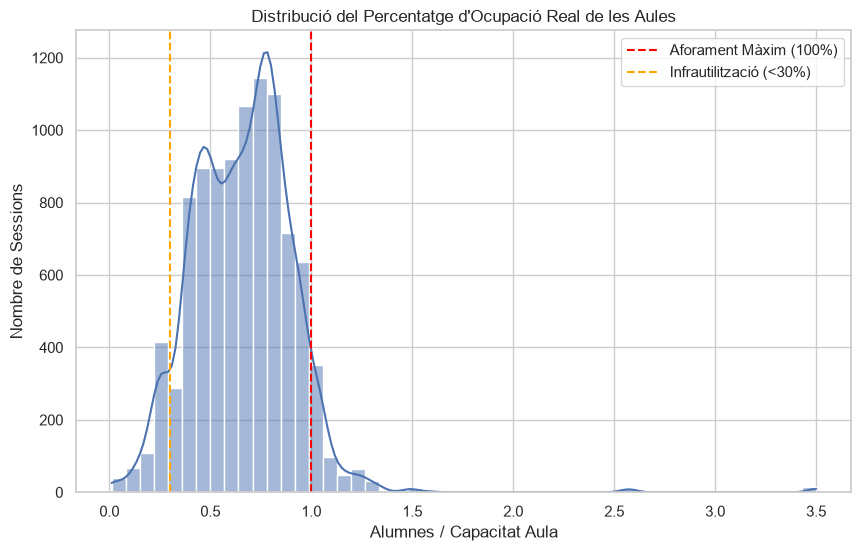

In [14]:
df_merge = sessions.merge(df_aules, left_on='aula_partida', right_on='aula', how='inner')
df_merge = df_merge[df_merge['alumnes'] > 0]
df_merge['pct_ocupacio'] = df_merge['alumnes'] / df_merge['capacitat']
infrautilitzades = df_merge[df_merge['pct_ocupacio'] < 0.3]

print(f"Total de sessions amb aules infrautilitzades (<30% ocupació): {len(infrautilitzades)}")

plt.figure(figsize=(10, 6))
sns.histplot(df_merge['pct_ocupacio'], bins=50, kde=True)
plt.axvline(1.0, color='red', linestyle='--', label='Aforament Màxim (100%)')
plt.axvline(0.3, color='orange', linestyle='--', label='Infrautilització (<30%)')
plt.title("Distribució del Percentatge d'Ocupació Real de les Aules")
plt.xlabel("Alumnes / Capacitat Aula")
plt.ylabel("Nombre de Sessions")
plt.legend()
plt.savefig(f'{directori_grafics}/ocupacio_real.png')
plt.show()

Obtenim un alt valor en 0, que hem filtrat ja que es deu a la naturalesa de les dades i no a dades reals

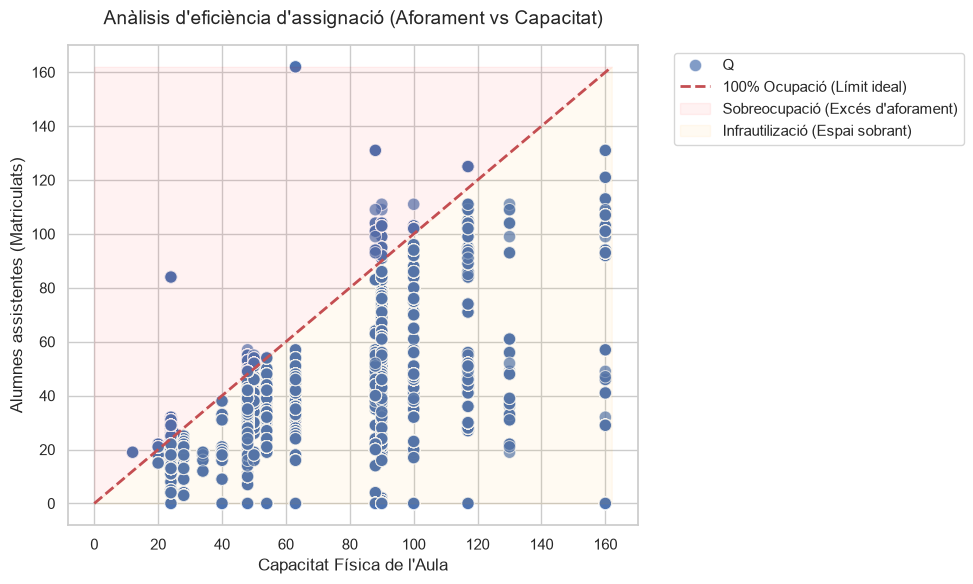

In [15]:
df = pd.merge(df_proposta, df_sessions[['id_sessio', 'alumnes']], on='id_sessio', how='left')
df = pd.merge(df, df_aules[['aula', 'capacitat', 'edifici']], on='aula', how='left')

df['alumnes'] = df['alumnes'].fillna(0)
df = df.dropna(subset=['capacitat'])

ordre_dies = ['L', 'M', 'X', 'J', 'V']
df['dia'] = pd.Categorical(df['dia'], categories=ordre_dies, ordered=True)
df = df.sort_values(['dia', 'h_ini'])

sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.max_open_warning': 0})

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='capacitat', y='alumnes', hue='edifici', alpha=0.7, s=80)

max_val = max(df['capacitat'].max(), df['alumnes'].max())
plt.plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='100% Ocupació (Límit ideal)')

plt.fill_between([0, max_val], [0, max_val], max_val, color='red', alpha=0.05, label='Sobreocupació (Excés d\'aforament)')
plt.fill_between([0, max_val], 0, [0, max_val], color='orange', alpha=0.05, label='Infrautilizació (Espai sobrant)')

plt.title('Anàlisis d\'eficiència d\'assignació (Aforament vs Capacitat)', fontsize=14, pad=15)
plt.xlabel('Capacitat Física de l\'Aula', fontsize=12)
plt.ylabel('Alumnes assistentes (Matriculats)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f'{directori_grafics}/eficiencia_asignacio.png', dpi=300)
plt.show()

In [18]:
def convert_types(obj):
    if isinstance(obj, (np.integer, np.int64, np.int32)):
        return int(obj)
    elif isinstance(obj, (np.floating, np.float64, np.float32)):
        return float(obj)
    return str(obj)

col_aula_id = next((c for c in df_aules.columns if 'aula' in c.lower() or 'codi' in c.lower()), df_aules.columns[0])
col_cap = next((c for c in df_aules.columns if 'capacitat' in c.lower() or 'aforament' in c.lower()), df_aules.columns[-1])
col_desc = next((c for c in df_aules.columns if 'descripcio' in c.lower() or 'nom' in c.lower()), None)

building_z = {'Q4': -60, 'Q3': -20, 'Q6': -20, 'Q2': 20, 'Q5': 20, 'Q1': 60, 'QC': 100, 'J': 140, 'B3': 140}
building_x_base = {'Q1': -120, 'Q2': -120, 'Q3': -120, 'Q4': -120, 'Q5': 20, 'Q6': 20, 'QC': -100, 'J': -120, 'B3': 20}

rows_parsed = []
for _, row in df_aules.iterrows():
    aula_id = str(row[col_aula_id]).strip()
    if aula_id == 'nan' or not aula_id:
        continue
        
    cap = float(row[col_cap]) if pd.notna(row[col_cap]) else 999.0
    parts = aula_id.split('/')
    if len(parts) >= 2:
        edifici = parts[0]
        codi = parts[1]
        
        piso = 0
        if len(codi) >= 4 and codi[0].isdigit():
            piso = int(codi[0])
        elif len(codi) >= 3 and codi[0].isdigit():
            piso = int(codi[0])
        elif '.' in codi:
            piso = int(codi[0])
            
        num = int(''.join(filter(str.isdigit, codi))) if any(str.isdigit(ch) for ch in codi) else 0
        desc = str(row[col_desc]) if col_desc and pd.notna(row[col_desc]) else ''
        
        rows_parsed.append({
            'id': aula_id,
            'edifici': edifici,
            'codi': codi,
            'piso': piso,
            'num': num,
            'desc': desc,
            'capacitat': cap
        })

df_parsed = pd.DataFrame(rows_parsed).sort_values(by=['edifici', 'piso', 'num'])

layout_3d = []
for (edifici, piso), group in df_parsed.groupby(['edifici', 'piso']):
    z = int(building_z.get(edifici, -100))
    y = int(piso * 18)
    x_base = int(building_x_base.get(edifici, -100))
    
    for idx, (_, room) in enumerate(group.iterrows()):
        layout_3d.append({
            'id': str(room['id']),
            'x': int(x_base + (idx * 18)),
            'y': int(y),
            'z': int(z),
            'desc': str(room['desc']),
            'capacitat': float(room['capacitat'])
        })

with open('layout.json', 'w', encoding='utf-8') as f:
    json.dump(layout_3d, f, ensure_ascii=False, default=convert_types)

capacitat_aules = {
    str(aula['id']): float(aula['capacitat'])
    for aula in layout_3d
}

print("Finalitzat correctament sense errors de serialització!")

s2 = df_sessions.copy()

if 'semestre' in s2.columns:
    s2_filtrat = s2[s2['semestre'].astype(str).str.contains('1')]
    if len(s2_filtrat) > 0:
        s2 = s2_filtrat

col_sess_aula = next((c for c in ['aula', 'codi_aula', 'aula_partida', 'espai'] if c in s2.columns), s2.columns[0])
s2 = s2.dropna(subset=[col_sess_aula])

def obtenir_blocs(row):
    try:
        h_str = str(row.get('h_ini', '0')).strip()
        if h_str == 'nan': return []
        
        if ':' in h_str:
            h = int(h_str.split(':')[0])
            m = int(h_str.split(':')[1])
        elif '.' in h_str:
            h = int(float(h_str))
            m = int((float(h_str) - h) * 60)
        else:
            h = int(h_str)
            m = 0
            
        durada = int(float(row.get('durada_min', 60)))
        
        start_mins = h * 60 + m
        end_mins = start_mins + durada
        
        start_h = start_mins // 60
        end_h = (end_mins - 1) // 60 
        
        blocs = []
        for current_h in range(start_h, end_h + 1):
            if 0 <= current_h < 24:
                blocs.append(f"{current_h:02d}:00")
        return blocs
    except Exception as e:
        return []

s2['blocs'] = s2.apply(obtenir_blocs, axis=1)
s2_exp = s2.explode('blocs')

def parse_dia(d):
    d = str(d).strip().upper()
    if 'L' in d or d == '1' or 'DILL' in d: return 'L'
    if ('M' in d and 'DI' not in d) or d == '2' or 'DIMAR' in d: return 'M'
    if 'X' in d or 'DIMEC' in d or d == '3' or d == 'DC': return 'X'
    if 'J' in d or 'DIJ' in d or d == '4' or d == 'DJ': return 'J'
    if 'V' in d or 'DIV' in d or d == '5' or d == 'DV': return 'V'
    return d

s2_exp['dia_net'] = s2_exp['dia'].apply(parse_dia) if 'dia' in s2_exp.columns else 'L'
s2_exp = s2_exp.dropna(subset=['blocs'])

col_alumnes = next((c for c in s2_exp.columns if any(x in c.lower() for x in ['alumn', 'matric', 'estud'])), None)
col_setmana = next((c for c in s2_exp.columns if 'setmana' in c.lower() or 'week' in c.lower()), None)

ocupacio = {'L':{}, 'M':{}, 'X':{}, 'J':{}, 'V':{}}
sessions_processades = 0

# NOU CÀLCUL: Primer agrupar per setmana i sumar
if col_setmana:
    # Si tenim columna de setmana, calculem l'ocupació concurrent
    agrupat_setmana = s2_exp.groupby(['dia_net', 'blocs', col_sess_aula, col_setmana])[col_alumnes].sum().reset_index() if col_alumnes else s2_exp.groupby(['dia_net', 'blocs', col_sess_aula, col_setmana]).size().reset_index(name='count')
    # Ara agafem el MÀXIM d'alumnes que hi ha hagut en qualsevol setmana
    agrupat_final = agrupat_setmana.groupby(['dia_net', 'blocs', col_sess_aula])[col_alumnes if col_alumnes else 'count'].max().reset_index()
else:
    # Fallback si no hi ha dades de setmana, utilitzar el mitjà per no excedir-se
    agrupat_final = s2_exp.groupby(['dia_net', 'blocs', col_sess_aula])[col_alumnes].mean().reset_index() if col_alumnes else s2_exp.groupby(['dia_net', 'blocs', col_sess_aula]).size().reset_index(name='count')

for _, row in agrupat_final.iterrows():
    dia = row['dia_net']
    hora = row['blocs']
    aula = str(row[col_sess_aula]).strip()
    alumnes_totals = row[col_alumnes if col_alumnes else 'count']
    
    if dia not in ocupacio:
        ocupacio[dia] = {}
    if hora not in ocupacio[dia]:
        ocupacio[dia][hora] = {}
        
    cap = capacitat_aules.get(aula, 999)
    
    if alumnes_totals > cap:
        ocupacio[dia][hora][aula] = 2
    else:
        ocupacio[dia][hora][aula] = 1
    sessions_processades += 1

with open('ocupacio.json', 'w', encoding='utf-8') as f:
    json.dump(ocupacio, f, ensure_ascii=False)

print(f"-> S'han guardat {sessions_processades} franges amb ocupació corregida a ocupacio.json")

print("3. Generant el visor3d.html...")
html_template = """<!DOCTYPE html>\n<html lang=\"ca\">\n<head>\n    <meta charset=\"UTF-8\">\n    <title>Visor 3D Aules UAB</title>\n    <link href=\"https://fonts.googleapis.com/css2?family=Nunito:wght@400;700&display=swap\" rel=\"stylesheet\">\n    <style>\n        body { \n            margin: 0; \n            overflow: hidden; \n            font-family: 'Nunito', 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; \n            background-color: #636e72;\n        }\n        #ui { position: absolute; bottom: 30px; left: 50%; transform: translateX(-50%); background: rgba(255,255,255,0.95); padding: 15px 35px; border-radius: 12px; display: flex; gap: 25px; box-shadow: 0 8px 32px rgba(0,0,0,0.2); }\n        .control { display: flex; flex-direction: column; gap: 8px; font-weight: 700; color: #2d3436; }\n        select, input[type=range] { cursor: pointer; }\n        select { padding: 5px; border-radius: 5px; border: 1px solid #b2bec3; font-family: 'Nunito', sans-serif; font-weight: 700; }\n        #legend { position: absolute; top: 20px; right: 20px; background: rgba(255,255,255,0.95); padding: 15px 20px; border-radius: 12px; box-shadow: 0 4px 15px rgba(0,0,0,0.15); color: #2d3436; font-weight: 700; }\n        .leg-item { display: flex; align-items: center; gap: 12px; margin-bottom: 10px; font-size: 15px; }\n        .leg-item:last-child { margin-bottom: 0; }\n        .box { width: 18px; height: 18px; border-radius: 4px; box-shadow: 0 2px 5px rgba(0,0,0,0.1); }\n        #info { position: absolute; top: 20px; left: 20px; background: rgba(45, 52, 54, 0.9); color: white; padding: 15px 20px; border-radius: 12px; pointer-events: none; display: none; box-shadow: 0 4px 15px rgba(0,0,0,0.2); font-size: 15px; line-height: 1.5; }\n        #info strong { color: #74b9ff; font-size: 18px; }\n    </style>\n    <script src=\"https://cdnjs.cloudflare.com/ajax/libs/three.js/r128/three.min.js\"></script>\n    <script src=\"https://cdn.jsdelivr.net/npm/three@0.128.0/examples/js/controls/OrbitControls.js\"></script>\n</head>\n<body>\n    <div id=\"legend\">\n        <div class=\"leg-item\"><div class=\"box\" style=\"background: #dfe6e9;\"></div>Lliure</div>\n        <div class=\"leg-item\"><div class=\"box\" style=\"background: #00b894;\"></div>Ocupada</div>\n        <div class=\"leg-item\"><div class=\"box\" style=\"background: #d63031;\"></div>Excés d'Aforament</div>\n    </div>\n    <div id=\"info\"></div>\n    <div id=\"ui\">\n        <div class=\"control\">\n            <label>Dia:</label>\n            <select id=\"dia\">\n                <option value=\"L\">Dilluns</option><option value=\"M\">Dimarts</option>\n                <option value=\"X\">Dimecres</option><option value=\"J\">Dijous</option>\n                <option value=\"V\">Divendres</option>\n            </select>\n        </div>\n        <div class=\"control\">\n            <label>Hora: <span id=\"hora-txt\">08:00</span></label>\n            <input type=\"range\" id=\"hora\" min=\"8\" max=\"20\" step=\"1\" value=\"8\" style=\"width: 200px;\">\n        </div>\n    </div>\n    <script>\n        let layout = [];\n        let ocupacio = {};\n        const rooms = {};\n\n        const scene = new THREE.Scene();\n        const camera = new THREE.PerspectiveCamera(50, window.innerWidth/window.innerHeight, 0.1, 1000);\n        camera.position.set(0, 150, 180);\n\n        const renderer = new THREE.WebGLRenderer({antialias: true, alpha: true});\n        renderer.setSize(window.innerWidth, window.innerHeight);\n        renderer.shadowMap.enabled = true;\n        renderer.shadowMap.type = THREE.PCFSoftShadowMap;\n        document.body.appendChild(renderer.domElement);\n        \n        const controls = new THREE.OrbitControls(camera, renderer.domElement);\n        controls.enableDamping = true;\n\n        const ambientLight = new THREE.AmbientLight(0xffffff, 0.85);\n        scene.add(ambientLight);\n        \n        const dirLight = new THREE.DirectionalLight(0xffffff, 0.4);\n        dirLight.position.set(50, 120, 80);\n        dirLight.castShadow = true;\n        scene.add(dirLight);\n\n        const geo = new THREE.BoxGeometry(14, 10, 14);\n        const terra = new THREE.Mesh(\n            new THREE.PlaneGeometry(350, 300), \n            new THREE.MeshLambertMaterial({color: 0x95a5a6})\n        );\n        terra.rotation.x = -Math.PI / 2;\n        terra.position.y = -5;\n        terra.receiveShadow = true;\n        scene.add(terra);\n\n        function createTextSprite(message) {\n            const canvas = document.createElement('canvas');\n            const context = canvas.getContext('2d');\n            canvas.width = 256; canvas.height = 128;\n            context.font = \"bold 32px 'Nunito', 'Segoe UI', Tahoma, sans-serif\";\n            context.shadowColor = \"rgba(255, 255, 255, 0.9)\";\n            context.shadowBlur = 6;\n            context.fillStyle = \"rgba(45, 52, 54, 1.0)\";\n            context.textAlign = \"center\";\n            context.textBaseline = \"middle\";\n            context.fillText(message, 128, 64);\n            const texture = new THREE.CanvasTexture(canvas);\n            const spriteMaterial = new THREE.SpriteMaterial({ map: texture, transparent: true });\n            const sprite = new THREE.Sprite(spriteMaterial);\n            sprite.scale.set(16, 8, 1);\n            return sprite;\n        }\n\n        function inicialitzarLayout(dataLayout) {\n            layout = dataLayout;\n            layout.forEach(aula => {\n                const mat = new THREE.MeshLambertMaterial({color: 0xdfe6e9});\n                const mesh = new THREE.Mesh(geo, mat);\n                mesh.position.set(aula.x, aula.y, aula.z);\n                mesh.castShadow = true;\n                mesh.receiveShadow = true;\n                mesh.userData = aula;\n                scene.add(mesh);\n                rooms[aula.id] = mesh;\n                \n                const edges = new THREE.EdgesGeometry(geo);\n                const line = new THREE.LineSegments(edges, new THREE.LineBasicMaterial({color: 0xb2bec3, linewidth: 2}));\n                mesh.add(line);\n                \n                const textSprite = createTextSprite(aula.id);\n                textSprite.position.y = 9;\n                mesh.add(textSprite);\n            });\n        }\n\n        function actualitzar() {\n            const dia = document.getElementById('dia').value;\n            const horaVal = document.getElementById('hora').value;\n            const horaStr = horaVal.padStart(2, '0') + ':00';\n            document.getElementById('hora-txt').textContent = horaStr;\n            \n            const dadesHora = (ocupacio[dia] && ocupacio[dia][horaStr]) ? ocupacio[dia][horaStr] : {};\n            \n            Object.keys(rooms).forEach(id => {\n                const estat = dadesHora[id] || 0;\n                let color = 0xdfe6e9;\n                if (estat === 1) color = 0x00b894;\n                if (estat === 2) color = 0xd63031;\n                rooms[id].material.color.setHex(color);\n            });\n        }\n\n        document.getElementById('dia').addEventListener('change', actualitzar);\n        document.getElementById('hora').addEventListener('input', actualitzar);\n\n        Promise.all([\n            fetch('layout.json').then(r => r.json()),\n            fetch('ocupacio.json').then(r => r.json())\n        ]).then(([layoutData, ocupacioData]) => {\n            ocupacio = ocupacioData;\n            inicialitzarLayout(layoutData);\n            actualitzar();\n        }).catch(err => console.error(\"Error carregant dades JSON. Comprova el servidor local.\", err));\n\n        const raycaster = new THREE.Raycaster();\n        const mouse = new THREE.Vector2();\n        const infoBox = document.getElementById('info');\n\n        window.addEventListener('mousemove', (e) => {\n            mouse.x = (e.clientX / window.innerWidth) * 2 - 1;\n            mouse.y = -(e.clientY / window.innerHeight) * 2 + 1;\n            raycaster.setFromCamera(mouse, camera);\n            const intersects = raycaster.intersectObjects(Object.values(rooms));\n            \n            if (intersects.length > 0) {\n                const data = intersects[0].object.userData;\n                infoBox.style.display = 'block';\n                infoBox.innerHTML = `<strong>${data.id}</strong><br>${data.desc}<br>Capacitat: ${data.capacitat}`;\n            } else {\n                infoBox.style.display = 'none';\n            }\n        });\n\n        function anim() {\n            requestAnimationFrame(anim);\n            controls.update();\n            renderer.render(scene, camera);\n        }\n        anim();\n    </script>\n</body>\n</html>\n"""
with open('visor3d.html', 'w', encoding='utf-8') as f:
    f.write(html_template)
print("Fet! Obrir 'visor3d.html' amb un servidor local per veure el resultat.")



Finalitzat correctament sense errors de serialització!


C:\Users\arnau\AppData\Local\Temp\ipykernel_8444\3901766138.py:117: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  s2['blocs'] = s2.apply(obtenir_blocs, axis=1)


-> S'han guardat 1539 franges amb ocupació corregida a ocupacio.json
3. Generant el visor3d.html...
Fet! Obrir 'visor3d.html' amb un servidor local per veure el resultat.
